In [121]:
%pip install pandas
%pip install numpy
%pip install requests
%pip install matplotlib
%pip install scipy

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [134]:
import pandas as pd
import numpy as np
from datetime import datetime, timezone
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy.stats import pearsonr 

Shutdown Data Visualization

In [92]:
shutdowns_df = pd.read_csv("internet-society-pulse-shutdowns.csv")
shutdowns_df

,country,start_date,end_date,type,verification_level,cause,affected_regions,affected_services
0,IN,2026-10-09 14:00:00+00:00,2026-10-10 14:00:00+00:00,regional,unconfirmed,protests,National Capital Territory of Delhi,Mobile Internet
1,IN,2026-10-02 01:00:00+00:00,2026-10-02 13:00:00+00:00,regional,unconfirmed,protests,National Capital Territory of Delhi,Mobile Internet
2,IQ,2026-09-28 03:20:00+00:00,2026-09-28 04:10:00+00:00,national,acknowledged,exams,NaN,NaN
3,IN,2026-09-27 16:00:00+00:00,2026-09-28 14:00:00+00:00,regional,unconfirmed,protests,Punjab,Mobile Internet
4,IQ,2026-09-26 03:20:00+00:00,2026-09-26 04:10:00+00:00,national,acknowledged,exams,NaN,NaN
...,...,...,...,...,...,...,...,...
973,IN,2019-01-05 00:00:00+00:00,2019-01-05 00:00:00+00:00,regional,confirmed,government_action,Jammu and Kashmir,NaN
974,IN,2019-01-03 00:00:00+00:00,2019-01-03 00:00:00+00:00,regional,unconfirmed,government_action,Jammu and Kashmir,Mobile Internet Services
975,IN,2019-01-02 00:00:00+00:00,2019-01-02 00:00:00+00:00,regional,unconfirmed,government_action,Jammu and Kashmir,Mobile Internet Services
976,CN,2019-01-01 00:00:00+00:00,NaN,content_blocking,confirmed,government_action,NaN,"WhatsApp, LinkedIn, YouTube, Reddit, Google, F..."


In [93]:
shutdowns_df["cause"].value_counts()

cause
government_action    401
exams                353
protests             147
war_conflict          41
elections             36
Name: count, dtype: int64

In [94]:
shutdowns_df["end_date_dt"] = shutdowns_df["end_date"].map(lambda x: datetime.fromisoformat(x) if isinstance(x, str) else datetime.now(timezone.utc))
shutdowns_df["start_date_dt"] = shutdowns_df["start_date"].map(lambda x: datetime.fromisoformat(x))
shutdowns_df["duration"] = shutdowns_df["end_date_dt"] - shutdowns_df["start_date_dt"]
shutdowns_df["duration_hours"] = shutdowns_df["duration"].dt.total_seconds() / 3600

In [95]:
exam_excluded_df = shutdowns_df[shutdowns_df["cause"] != "exams"]
country_grouped = exam_excluded_df.groupby("country")
multiple_shutdowns = country_grouped.filter(lambda x: len(x) > 5)
multiple_shutdowns.sort_values("country").reset_index(drop=True)

,country,start_date,end_date,type,verification_level,cause,affected_regions,affected_services,end_date_dt,start_date_dt,duration,duration_hours
0,BD,2019-12-31 00:00:00+00:00,2020-01-02 00:00:00+00:00,regional,unconfirmed,government_action,"Rangpur, Rajshahi, Khulna","Mobile Internet Services, SMS",2020-01-02 00:00:00+00:00,2019-12-31 00:00:00+00:00,2 days 00:00:00,48.0
1,BD,2019-09-09 00:00:00+00:00,2020-08-28 00:00:00+00:00,regional,unconfirmed,government_action,Chittagong,Internet Services,2020-08-28 00:00:00+00:00,2019-09-09 00:00:00+00:00,354 days 00:00:00,8496.0
2,BD,2023-10-28 11:00:00+00:00,2023-10-28 20:00:00+00:00,regional,acknowledged,protests,Dhaka,Internet Services,2023-10-28 20:00:00+00:00,2023-10-28 11:00:00+00:00,0 days 09:00:00,9.0
3,BD,2019-09-02 00:00:00+00:00,2019-09-09 00:00:00+00:00,regional,unconfirmed,government_action,Chittagong,Mobile Internet Services,2019-09-09 00:00:00+00:00,2019-09-02 00:00:00+00:00,7 days 00:00:00,168.0
4,BD,2024-08-04 07:30:00+00:00,2024-08-05 07:30:00+00:00,national,confirmed,protests,NaN,Internet Services,2024-08-05 07:30:00+00:00,2024-08-04 07:30:00+00:00,1 days 00:00:00,24.0
...,...,...,...,...,...,...,...,...,...,...,...,...
518,YE,2020-10-15 00:00:00+00:00,2020-10-15 01:00:00+00:00,regional,unconfirmed,government_action,Hadhramaut,Internet Services,2020-10-15 01:00:00+00:00,2020-10-15 00:00:00+00:00,0 days 01:00:00,1.0
519,YE,2020-08-19 00:00:00+00:00,2020-08-19 04:00:00+00:00,regional,unconfirmed,war_conflict,Zanzibar,Internet Services,2020-08-19 04:00:00+00:00,2020-08-19 00:00:00+00:00,0 days 04:00:00,4.0
520,YE,2020-01-30 00:00:00+00:00,2020-02-26 00:00:00+00:00,national,unconfirmed,government_action,NaN,Internet Services,2020-02-26 00:00:00+00:00,2020-01-30 00:00:00+00:00,27 days 00:00:00,648.0
521,YE,2022-01-20 21:30:00+00:00,2022-01-24 00:00:00+00:00,national,confirmed,war_conflict,NaN,Internet Services,2022-01-24 00:00:00+00:00,2022-01-20 21:30:00+00:00,3 days 02:30:00,74.5


In [96]:
multiple_shutdowns["country"].value_counts()

country
IN    407
PK     18
VE     18
IR     16
BD     10
ET      9
MM      9
IQ      8
SD      8
YE      8
MZ      6
BY      6
Name: count, dtype: int64

/var/folders/qy/ty38b_c12590n_rw3ygn59840000gn/T/ipykernel_87982/666097201.py:14: UserWarning: no explicit representation of timezones available for np.datetime64
  corr = pearsonr(np.array(x, dtype=np.datetime64).astype(np.int64), y)


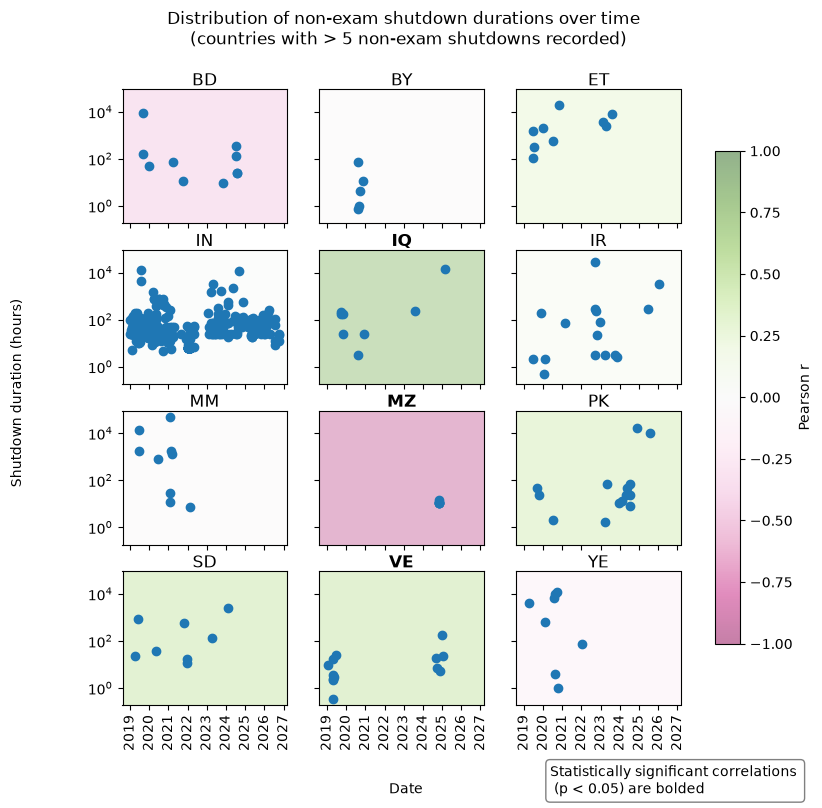

In [159]:
nrows = 4
ncols = 3
fig, axes = plt.subplots(nrows, ncols, figsize=(3 * ncols, 2 * nrows), sharex=True, sharey=True)

cmap = mpl.colormaps["PiYG"]
norm = mpl.colors.Normalize(vmin=-1, vmax=1)
for ax, (name, group) in zip(axes.flat, multiple_shutdowns.groupby("country")):
    x = group["start_date_dt"]
    y = group["duration_hours"]
    ax.scatter(x, y)
    ax.set_yscale('log')
    ax.tick_params("x", rotation=90)

    corr = pearsonr(np.array(x, dtype=np.datetime64).astype(np.int64), y)
    ax.set_facecolor(cmap(norm(corr.statistic), alpha=0.3))
    if (corr.pvalue < 0.05):
        ax.set_title(name, fontweight="bold", pad=-5)
    else:
        ax.set_title(name, pad=-5)

fig.suptitle("Distribution of non-exam shutdown durations over time \n (countries with > 5 non-exam shutdowns recorded)", x=0.44)
fig.text(0.44, 0, "Date", ha="center")
fig.text(0, 0.5, "Shutdown duration (hours)", va="center", rotation="vertical")
fig.colorbar(mpl.cm.ScalarMappable(norm=norm, cmap=cmap), ax=axes, label="Pearson r", alpha=0.5, shrink=0.8)
fig.text(0.6, 0, "Statistically significant correlations \n (p < 0.05) are bolded", bbox=dict(boxstyle="round", facecolor="white", edgecolor="grey"))

plt.savefig("output/shutdown_duration_trends.png")